# 1. Datos y EDA mejorado

Este capítulo retoma el EDA del primer entregable y lo **corrige y amplía** con los
hallazgos encontrados durante el modelado (Sección 7.1 de la guía). Los cambios principales son:

| # | Corrección / mejora | Impacto en el modelado |
|---|---|---|
| 1 | Se verificó una **identidad contable exacta**: `BrentEquivalentProductionCost = WellheadProductionCost + BrentDifferential` | `BrentDifferential` es un sumando del target → se modela en dos escenarios (A sin BD, B con BD) |
| 2 | La misma identidad explica el VIF ≈ 10⁹ y el PC5 ≈ 0 del entregable 1 (`BEDC = WDC + BD`) | El VIF se recalcula sin la combinación lineal exacta |
| 3 | Mecanismo de faltantes con evidencia: 2014 llega casi vacío (99.6 %) y, en 2015–2023, `Production` falta **en el 100 % de África, Asia Central y ~94 % de Asia Oriental** y en 0 % del resto | Imputación por mediana + indicador de faltante dentro del Pipeline |
| 4 | Información mutua y R² univariado (auditoría de fuga cuantitativa) | Se confirma qué variables son proxies del target |
| 5 | V de Cramér entre categóricas: jerarquía País → Región → OPEP | Redundancia esperada; se mantiene por los modelos de árboles |
| 6 | Tamaños de efecto (ε²) con corrección de Holm para todas las categóricas | Prioridad de variables y espacio de búsqueda |
| 7 | Deriva temporal (2015–2018 vs 2019–2023) | Justifica `Year` como predictora |
| 8 | `SupplyTypeName` y `Commodity` son constantes | Se eliminan (en el entregable 1 `SupplyTypeName` entraba al modelo) |

Las decisiones que alimentan el modelo (información mutua, R² univariado) se calculan **solo con el
conjunto de desarrollo** (80 %), nunca con el de prueba.

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from src import config as C
from src.data import load_raw, load_model_data, split_dev_test
from src.stats_tests import holm
from src.viz import set_style, SERIES, INK2, MUTED

C.set_global_seed()
set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

raw = load_raw()
df = load_model_data()
dev, test = split_dev_test(df)
print(f"Filas crudas: {raw.shape[0]:,} | con target: {df.shape[0]:,} | desarrollo: {len(dev):,} | prueba: {len(test):,}")
print(f"Activos: {df[C.GROUP].nunique()} (desarrollo {dev[C.GROUP].nunique()}, prueba {test[C.GROUP].nunique()}; sin solapamiento: "
      f"{len(set(dev[C.GROUP]) & set(test[C.GROUP])) == 0})")

Filas crudas: 4,595 | con target: 3,834 | desarrollo: 3,085 | prueba: 749
Activos: 695 (desarrollo 556, prueba 139; sin solapamiento: True)


## 1.1 Hallazgo clave: identidad contable en el target

El VIF de 1.5 × 10⁹ y la quinta componente principal con varianza ≈ 0 del entregable 1 indican
una **combinación lineal exacta** entre variables. Se verifica directamente:

In [2]:
d = raw.dropna(subset=[C.TARGET, "WellheadProductionCost", "BrentDifferential"])
res_p = d[C.TARGET] - (d["WellheadProductionCost"] + d["BrentDifferential"])
d2 = raw.dropna(subset=["BrentEquivalentDevelopmentCost", "WellheadDevelopmentCost", "BrentDifferential"])
res_d = d2["BrentEquivalentDevelopmentCost"] - (d2["WellheadDevelopmentCost"] + d2["BrentDifferential"])
identidad = pd.DataFrame({
    "Identidad": ["BEPC = WPC + BD", "BEDC = WDC + BD"],
    "Filas verificadas": [len(res_p), len(res_d)],
    "Error absoluto máx.": [res_p.abs().max(), res_d.abs().max()],
    "% filas con error ≤ 0.01": [100 * (res_p.abs() <= 0.0101).mean(), 100 * (res_d.abs() <= 0.0101).mean()],
})
identidad

,Identidad,Filas verificadas,Error absoluto máx.,% filas con error ≤ 0.01
0,BEPC = WPC + BD,3023,0.010,100.000
1,BEDC = WDC + BD,3511,0.010,100.000


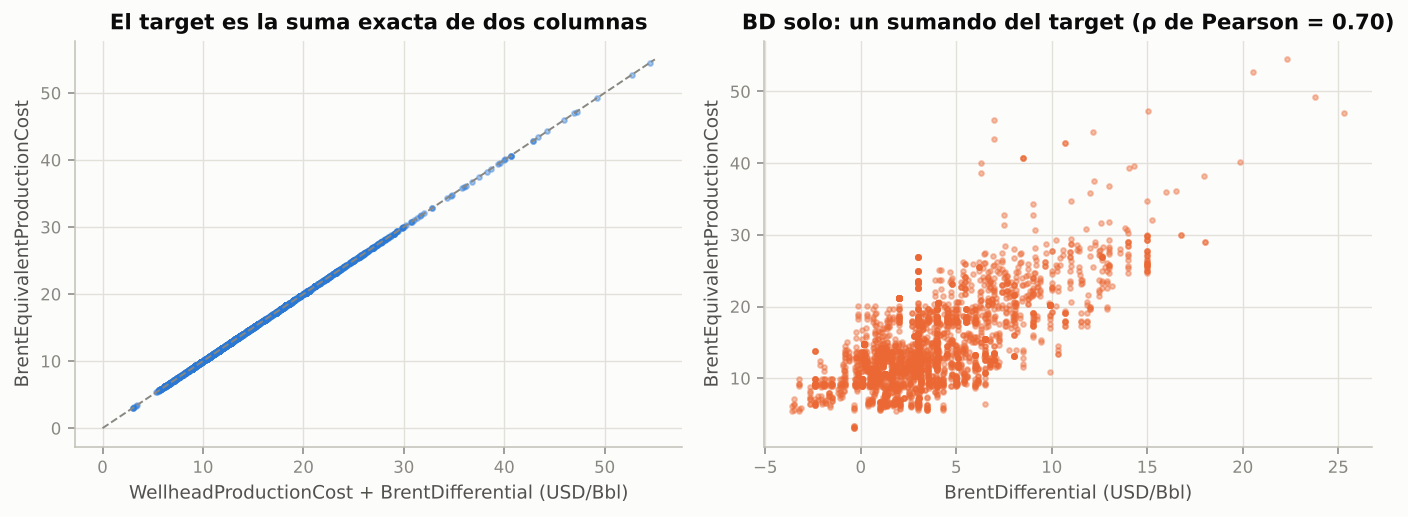

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].scatter(d["WellheadProductionCost"] + d["BrentDifferential"], d[C.TARGET], s=6, alpha=0.4, color=SERIES[0])
axes[0].plot([0, 55], [0, 55], color=MUTED, lw=1, ls="--")
axes[0].set(xlabel="WellheadProductionCost + BrentDifferential (USD/Bbl)", ylabel="BrentEquivalentProductionCost",
            title="El target es la suma exacta de dos columnas")
axes[1].scatter(d["BrentDifferential"], d[C.TARGET], s=6, alpha=0.4, color=SERIES[1])
axes[1].set(xlabel="BrentDifferential (USD/Bbl)", ylabel="BrentEquivalentProductionCost",
            title="BD solo: un sumando del target (ρ de Pearson = %.2f)" % d[[C.TARGET, "BrentDifferential"]].corr().iloc[0, 1])
plt.tight_layout()

**Interpretación.** En el 100 % de las filas con datos completos el target es exactamente la suma de
`WellheadProductionCost` y `BrentDifferential` (el error máximo de 0.01 es redondeo a centavos). Lo
mismo ocurre con el costo de desarrollo. Consecuencias:

- `WellheadProductionCost` es una fuga total y ya estaba excluida (correcto en el entregable 1).
- `BrentDifferential` **no** es un proxy cualquiera: es un sumando del target. Incluirlo convierte parte
  del problema en una suma conocida, lo que infla el R² (≈ 0.85 vs ≈ 0.77 sin BD con el mismo modelo lineal).
- Desde negocio, el diferencial (calidad del crudo, transporte, descuento frente al Brent) puede conocerse
  antes que el costo de cabeza de pozo, por lo que **no es ilegítimo** en todos los escenarios de uso.

**Decisión:** el escenario principal (**A, estructural**) excluye `BrentDifferential`; el escenario
**B** lo incluye como análisis de sensibilidad. Ambos se comparan formalmente con el test de Clark-West
(B anida a A) en el capítulo 5.

## 1.2 Multicolinealidad corregida (VIF)

El VIF se recalcula de dos formas: con el conjunto original (que contiene la combinación lineal
exacta) y sin `BrentEquivalentDevelopmentCost` (= WDC + BD).

In [4]:
from sklearn.linear_model import LinearRegression

def vif(frame):
    X = frame.dropna().to_numpy(float)
    out = {}
    for j, c in enumerate(frame.columns):
        others = np.delete(X, j, axis=1)
        r2 = LinearRegression().fit(others, X[:, j]).score(others, X[:, j])
        out[c] = 1 / max(1 - r2, 1e-12)
    return pd.Series(out)

cols_orig = ["BrentDifferential", "WellheadDevelopmentCost", "BrentEquivalentDevelopmentCost", "WellheadProductionCost", "Production"]
cols_fix = ["BrentDifferential", "WellheadDevelopmentCost", "WellheadProductionCost", "Production"]
pd.DataFrame({"VIF original (E1)": vif(raw[cols_orig]), "VIF sin BEDC": vif(raw[cols_fix])})

,VIF original (E1),VIF sin BEDC
BrentDifferential,"8,261,402.992",1.068
BrentEquivalentDevelopmentCost,"95,632,293.152",NaN
Production,1.107,1.107
WellheadDevelopmentCost,"88,858,386.914",2.030
WellheadProductionCost,2.022,2.021


**Interpretación.** Al retirar la columna que es combinación lineal exacta, todos los VIF quedan en torno
a 2 o menos: la "multicolinealidad extrema" del entregable 1 no era una propiedad de los datos sino un artefacto
de la identidad contable (los VIF restantes están entre 1.07 y 2.03). Las variables numéricas que entran al modelo (`Year`, `Production` y, en el
escenario B, `BrentDifferential`) no presentan colinealidad problemática.

## 1.3 Mecanismo de los valores faltantes

El entregable 1 clasificó los faltantes como "MAR o MNAR" de forma preliminar. Aquí se aporta evidencia.

In [5]:
miss_year = raw.assign(**{c: raw[c].isna() for c in ["Production", C.TARGET, "BrentDifferential"]}) \
    .groupby("Year")[["Production", C.TARGET, "BrentDifferential"]].mean().mul(100)
miss_year.round(1).T

Year,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
Production,99.600,21.800,22.300,24.100,22.800,21.100,21.100,21.000,21.000,22.600
BrentEquivalentProductionCost,99.600,1.200,1.000,0.800,1.200,0.900,1.100,0.900,0.900,0.700
BrentDifferential,99.600,1.900,1.900,1.600,1.700,1.100,1.100,1.100,1.100,1.200


In [6]:
m = df.copy()
m["prod_missing"] = m["Production"].isna()
m_no2014 = m[m["Year"] > 2014]
a = m_no2014.loc[m_no2014["prod_missing"], C.TARGET]
b = m_no2014.loc[~m_no2014["prod_missing"], C.TARGET]
u = stats.mannwhitneyu(a, b)
rb = 1 - 2 * u.statistic / (len(a) * len(b))
tab = pd.crosstab(m_no2014["RegionName"], m_no2014["prod_missing"])
chi2, p_chi, dof, _ = stats.chi2_contingency(tab)
cramer = np.sqrt(chi2 / (tab.values.sum() * (min(tab.shape) - 1)))
pd.DataFrame({
    "Prueba": ["Mann-Whitney: target (Production faltante vs observado, 2015–2023)",
               "χ²: faltante de Production vs Región (2015–2023)"],
    "Estadístico": [u.statistic, chi2], "p-valor": [u.pvalue, p_chi],
    "Tamaño de efecto": [f"r biserial = {rb:.3f}", f"V de Cramér = {cramer:.3f}"],
})

,Prueba,Estadístico,p-valor,Tamaño de efecto
0,Mann-Whitney: target (Production faltante vs o...,"1,004,365.000",0.000,r biserial = 0.180
1,χ²: faltante de Production vs Región (2015–2023),"3,785.923",0.000,V de Cramér = 0.994


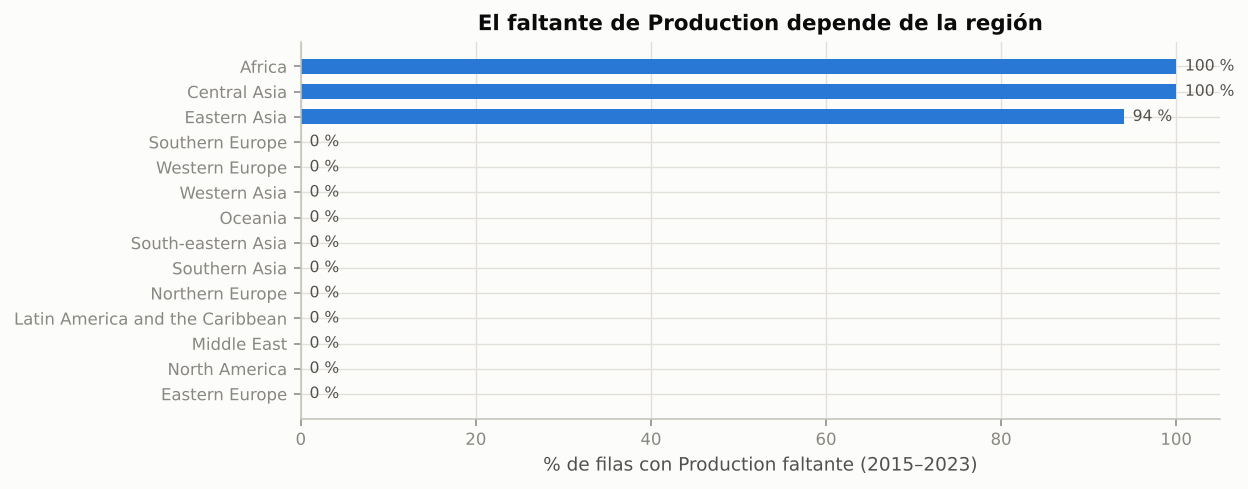

In [7]:
fig, ax = plt.subplots(figsize=(9, 3.6))
rate = m_no2014.groupby("RegionName")["prod_missing"].mean().sort_values() * 100
ax.barh(rate.index, rate.values, color=SERIES[0], height=0.6)
ax.set(xlabel="% de filas con Production faltante (2015–2023)", title="El faltante de Production depende de la región")
for y_, v in enumerate(rate.values):
    ax.text(v + 1, y_, f"{v:.0f} %", va="center", fontsize=8, color=INK2)
plt.tight_layout()

**Interpretación.**

- En **2014** el 99.6 % de las filas no tiene `Production`, `BrentDifferential` ni target: el año
  prácticamente no fue reportado (faltante **estructural**). Solo 3 filas de 2014 llegan al modelado.
- Entre 2015 y 2023 el faltante de `Production` está **casi determinado por la región** (V de Cramér ≈ 0.99):
  falta en el 100 % de los activos de África y Asia Central y en el 94 % de Asia Oriental, y en ninguno de
  las demás regiones. Es un patrón de cobertura de la fuente de datos, no del valor de la producción.
- Las filas sin producción tienen un target ligeramente distinto (r biserial = 0.18, efecto pequeño), lo que
  también descarta **MCAR**. La evidencia apunta a **MAR** condicionado a la región (variable observada).
- Implicación: para esas regiones el modelo nunca ve producción real; el indicador de faltante se vuelve
  equivalente a "región sin cobertura", información que ya aportan las variables geográficas.
- **Decisión:** imputación por mediana **más un indicador de faltante** dentro del Pipeline; el indicador
  permite que el modelo aprenda el patrón de ausencia en lugar de ocultarlo. Las filas sin target se
  descartan (no se imputa la variable objetivo).

## 1.4 Asociación entre categóricas (V de Cramér)

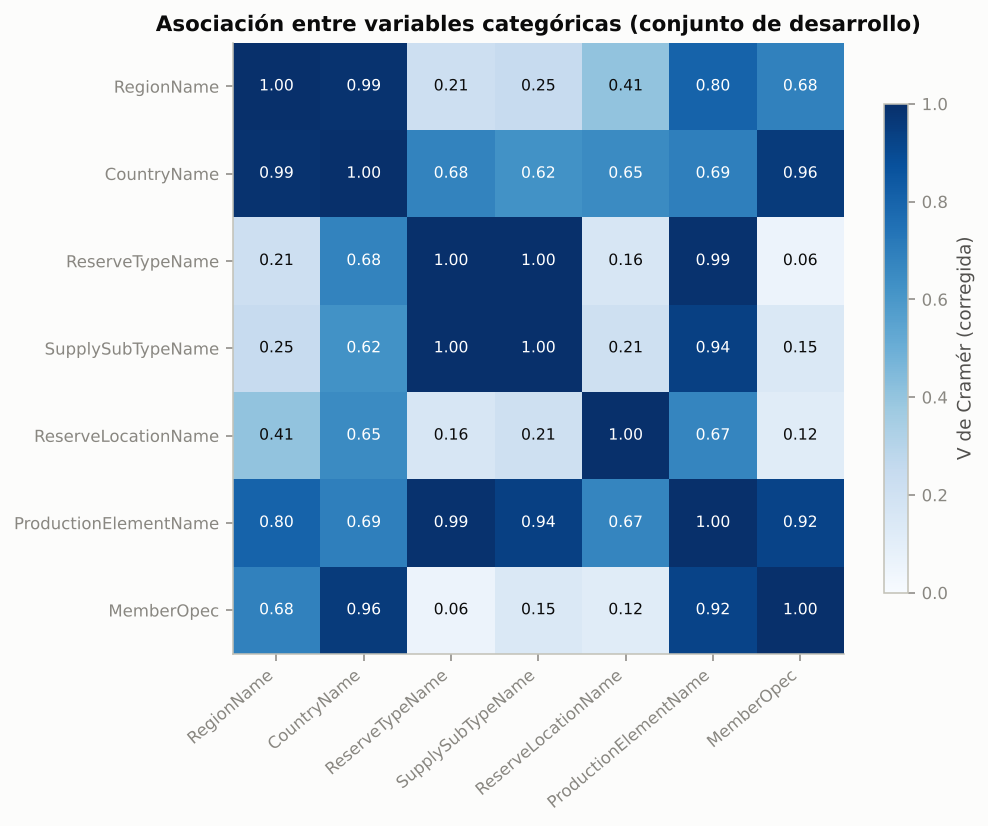

In [8]:
cats = C.CATEGORICAL
def cramers_v(x, y):
    t = pd.crosstab(x, y)
    c2 = stats.chi2_contingency(t, correction=False)[0]
    n = t.values.sum()
    r, k = t.shape
    # corrección de sesgo de Bergsma (2013)
    phi2 = max(0, c2 / n - (k - 1) * (r - 1) / (n - 1))
    rc, kc = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2 / max(min(kc - 1, rc - 1), 1e-9))

V = pd.DataFrame([[cramers_v(dev[a], dev[b]) for b in cats] for a in cats], index=cats, columns=cats)
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(V.values, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(cats)), cats, rotation=40, ha="right")
ax.set_yticks(range(len(cats)), cats)
ax.grid(False)
for i in range(len(cats)):
    for j in range(len(cats)):
        ax.text(j, i, f"{V.values[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if V.values[i, j] > 0.6 else "#0b0b0b")
fig.colorbar(im, ax=ax, shrink=0.8, label="V de Cramér (corregida)")
ax.set_title("Asociación entre variables categóricas (conjunto de desarrollo)")
plt.tight_layout()

**Interpretación.** Existe una jerarquía casi determinística: el país define la región y la pertenencia a
la OPEP (V ≈ 1), y la cuenca productiva (`ProductionElementName`) está fuertemente asociada al país. Para
modelos lineales esto genera redundancia (que Ridge/Lasso manejan con regularización); para árboles no es
un problema. Se mantienen todas porque aportan distinta granularidad: `RegionName` generaliza a países con
pocos activos (45 de 99 países tienen un solo activo).

## 1.5 Variables categóricas frente al target: Kruskal-Wallis + ε² con Holm

In [9]:
rows = []
for c in cats:
    groups = [g[C.TARGET].values for _, g in dev.groupby(c) if len(g) >= 2]
    h, p = stats.kruskal(*groups)
    n, k = sum(map(len, groups)), len(groups)
    eps2 = (h - k + 1) / (n - k)  # épsilon cuadrado (tamaño de efecto de Kruskal-Wallis)
    rows.append({"variable": c, "categorías": dev[c].nunique(), "H": h, "p_crudo": p, "ε²": eps2})
kw = pd.DataFrame(rows)
kw["p_Holm"] = holm(kw["p_crudo"])
kw["magnitud"] = pd.cut(kw["ε²"], [-1, 0.01, 0.06, 0.14, 1], labels=["despreciable", "pequeña", "mediana", "grande"])
kw.sort_values("ε²", ascending=False).reset_index(drop=True)

,variable,categorías,H,p_crudo,ε²,p_Holm,magnitud
0,ProductionElementName,64,"2,585.256",0.000,0.835,0.000,grande
1,CountryName,87,"2,342.428",0.000,0.753,0.000,grande
2,RegionName,14,"1,811.228",0.000,0.586,0.000,grande
3,SupplySubTypeName,5,380.023,0.000,0.122,0.000,mediana
4,ReserveTypeName,2,266.527,0.000,0.086,0.000,mediana
5,MemberOpec,2,206.697,0.000,0.067,0.000,mediana
6,ReserveLocationName,3,177.726,0.000,0.057,0.000,pequeña


**Interpretación.** Con n ≈ 3.000 todas las pruebas son significativas incluso tras Holm, por eso la
lectura relevante es el **tamaño de efecto**: las variables geográficas finas (país, cuenca) y el
región explican la mayor parte de la variabilidad del costo (ε² grande, 0.59–0.84); el subtipo de
suministro, el tipo de reserva y la OPEP tienen efectos medianos (0.07–0.12) y la ubicación
(onshore/offshore) uno pequeño. Esto anticipa que los modelos con
interacciones (árboles, boosting, KNN) superen a los lineales.

## 1.6 Auditoría de fuga cuantitativa: información mutua y R² univariado

Para cada variable se mide (i) la información mutua con el target y (ii) el R² de validación cruzada
por grupos de un modelo que usa **solo esa variable**. Un R² univariado cercano a 1 es señal de fuga.

In [10]:
from sklearn.feature_selection import mutual_info_regression
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.ensemble import HistGradientBoostingRegressor

cand = ["Year", "Production", "BrentDifferential", "WellheadProductionCost", "WellheadDevelopmentCost",
        "BrentEquivalentDevelopmentCost"] + cats
rows = []
y_dev = dev[C.TARGET].to_numpy()
for c in cand:
    col = dev[c]
    is_cat = col.dtype == object or str(col.dtype).startswith(("str", "string", "category"))
    x = pd.factorize(col)[0].reshape(-1, 1).astype(float) if is_cat else col.to_numpy(float).reshape(-1, 1)
    mask = ~np.isnan(x[:, 0])
    mi = mutual_info_regression(x[mask], y_dev[mask], discrete_features=is_cat, random_state=C.SEED)[0]
    model = HistGradientBoostingRegressor(max_iter=150, random_state=C.SEED,
                                          categorical_features=[0] if is_cat else None)
    r2 = cross_val_score(model, x[mask], y_dev[mask], groups=dev[C.GROUP].to_numpy()[mask],
                         cv=GroupKFold(5), scoring="r2").mean()
    rows.append({"variable": c, "MI (nats)": mi, "R² univariado (GroupKFold)": r2, "n": int(mask.sum())})
leak = pd.DataFrame(rows).sort_values("R² univariado (GroupKFold)", ascending=False).reset_index(drop=True)
x2 = dev[["WellheadProductionCost", "BrentDifferential"]].dropna()
r2_pair = cross_val_score(LinearRegression(), x2, dev.loc[x2.index, C.TARGET], groups=dev.loc[x2.index, C.GROUP],
                          cv=GroupKFold(5), scoring="r2").mean()
print(f"R² (GroupKFold) de una regresión lineal con WPC + BD: {r2_pair:.4f}  -> fuga total")
leak

R² (GroupKFold) de una regresión lineal con WPC + BD: 1.0000  -> fuga total


,variable,MI (nats),R² univariado (GroupKFold),n
0,WellheadProductionCost,1.668,0.703,2416
1,ProductionElementName,1.993,0.669,3085
2,CountryName,1.543,0.577,3085
3,BrentEquivalentDevelopmentCost,2.712,0.533,3045
4,BrentDifferential,1.174,0.525,3038
5,RegionName,1.139,0.466,3085
6,WellheadDevelopmentCost,1.353,0.417,2839
7,SupplySubTypeName,0.232,0.206,3085
8,ReserveTypeName,0.102,0.196,3085
9,ReserveLocationName,0.249,0.070,3085


**Interpretación.**

- `WellheadProductionCost` tiene el R² univariado más alto (0.70) y, junto con `BrentDifferential`,
  reconstruye el target con R² = 1.0000: fuga total, correctamente excluida.
- `BrentEquivalentDevelopmentCost` tiene la mayor información mutua (2.7 nats) porque comparte el sumando BD.
- `BrentDifferential` tiene R² univariado moderado: es un componente, no una copia. Por eso se trata como
  escenario de sensibilidad (B) y no se elimina de toda discusión.
- Las variables geográficas (`CountryName`, `ProductionElementName`) tienen R² univariado alto (0.58–0.67) pero
  legítimo: son características estructurales conocidas antes de producir. Como la partición es **por
  activo**, el modelo no puede memorizar activos individuales.
- El identificador del activo (`CostProductionElementName`) nunca entra al modelo; solo define grupos.

## 1.7 Componente temporal y deriva

KS 2015–18 vs 2019–23: D = 0.104, p = 2.68e-09
Desv. estándar total del target: 5.54 | desv. estándar media dentro de cada activo: 1.37


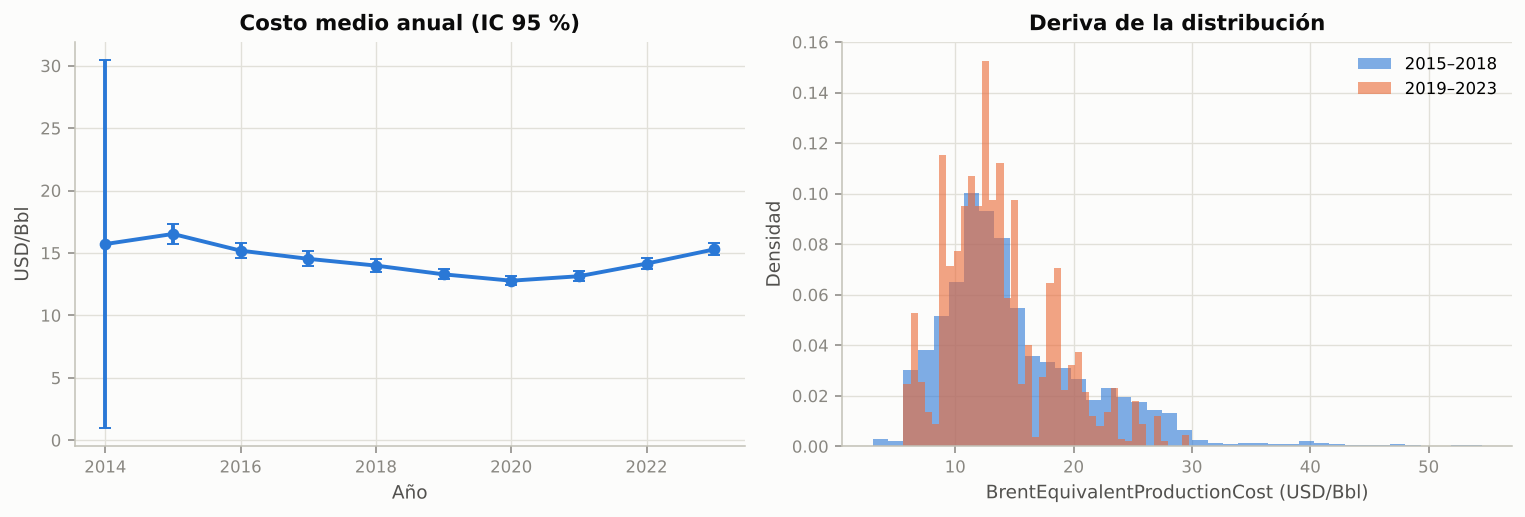

In [11]:
yr = df.groupby("Year")[C.TARGET].agg(["mean", "median", "count", "std"])
yr["ic95"] = 1.96 * yr["std"] / np.sqrt(yr["count"])
early = df.loc[df["Year"].between(2015, 2018), C.TARGET]
late = df.loc[df["Year"].between(2019, 2023), C.TARGET]
ks = stats.ks_2samp(early, late)
within = df.groupby(C.GROUP)[C.TARGET].std().mean()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].errorbar(yr.index, yr["mean"], yerr=yr["ic95"], color=SERIES[0], marker="o", capsize=3, lw=2)
axes[0].set(xlabel="Año", ylabel="USD/Bbl", title="Costo medio anual (IC 95 %)")
axes[1].hist(early, bins=40, alpha=0.6, density=True, color=SERIES[0], label="2015–2018")
axes[1].hist(late, bins=40, alpha=0.6, density=True, color=SERIES[1], label="2019–2023")
axes[1].set(xlabel="BrentEquivalentProductionCost (USD/Bbl)", ylabel="Densidad", title="Deriva de la distribución")
axes[1].legend()
plt.tight_layout()
print(f"KS 2015–18 vs 2019–23: D = {ks.statistic:.3f}, p = {ks.pvalue:.2e}")
print(f"Desv. estándar total del target: {df[C.TARGET].std():.2f} | desv. estándar media dentro de cada activo: {within:.2f}")

**Interpretación.**

- El costo medio cae de ~16.5 USD/Bbl (2015) a ~12.8 (2020) y se recupera a ~15.3 (2023): forma de U
  asociada al ciclo de precios (caída 2015–2016, COVID 2020, inflación de costos 2022–2023).
- La prueba KS confirma **deriva** entre periodos, aunque con un estadístico D moderado.
- La variabilidad **dentro** de cada activo (σ ≈ 1.4) es cuatro veces menor que la total (σ ≈ 5.5): la
  mayor parte de la varianza es **entre activos**. Esto justifica la partición por grupos (GroupKFold por
  activo): una partición aleatoria pondría años del mismo activo en entrenamiento y prueba y el modelo
  "recordaría" el nivel de costo de ese activo.
- `Year` se mantiene como predictora numérica para capturar el ciclo común.

## 1.8 Resumen: del EDA a las decisiones del pipeline

| Hallazgo del EDA | Decisión en el pipeline |
|---|---|
| Target = WPC + BD (identidad exacta) | Excluir WPC; BD solo en el escenario B |
| Varianza dominada por diferencias entre activos | `GroupKFold` por activo en el hold-out, bucle externo e interno |
| Production con asimetría 6.8 y faltantes MAR/estructurales | `log1p` + imputación por mediana + indicador de faltante |
| Target con asimetría 1.5 y colas pesadas | Optimizar RMSE, reportar también MAE y MAPE; residuos con pruebas robustas |
| Categóricas de alta cardinalidad y efecto grande | One-Hot con agrupación de categorías raras (< 5 casos) |
| Jerarquía País → Región → OPEP | Se conservan; los modelos regularizados y de árboles gestionan la redundancia |
| Deriva temporal moderada | `Year` como predictora; análisis de autocorrelación de residuos (Ljung-Box, BDS) |
| Commodity y SupplyTypeName constantes | Se eliminan |